# IMPLEMENT DECISION TREE


Dataset Head:


,FlowerId,ObservationId,SampleId,PlantId,Species,SpeciesCode,Variety,Subspecies,PhenotypeId,SepalLengthCm,...,ImageBrightness,ImageSharpness,ImageBlurScore,ImageBackgroundType,MeasurementErrorScore,InstrumentPrecision,ObserverConfidence,MeasurementQuality,OutlierFlag,AnomalyScore
0,1,OBS000001,SMP000001,PLT18115,Iris-virginica,VIR,Delta,subsp.3,PH03434,6.62,...,0.446,0.621,0.125,White,0.151,0.5 cm,0.791,High,False,0.046
1,2,OBS000002,SMP000002,PLT06232,Iris-versicolor,VER,Beta,subsp.3,PH01914,5.83,...,0.698,0.799,0.263,Natural,0.085,1 mm,0.905,High,False,0.115
2,3,OBS000003,SMP000003,PLT15597,Iris-virginica,VIR,NaN,subsp.2,PH03492,6.03,...,0.683,0.707,0.158,Field,0.073,1 mm,0.821,High,False,0.010
3,4,OBS000004,SMP000004,PLT11227,Iris-virginica,VIR,Gamma,NaN,PH02138,7.66,...,0.306,0.490,0.194,Field,0.125,0.1 cm,0.747,High,False,0.109
4,5,OBS000005,SMP000005,PLT16873,Iris-setosa,SET,Gamma,NaN,PH00242,4.81,...,0.847,0.761,0.253,White,0.000,1 mm,1.000,NaN,False,0.174


Dropping 45 non-numeric columns from X: ['SpeciesCode', 'Variety', 'Subspecies', 'PhenotypeId', 'SepalTipShape', 'SepalColor', 'SepalTexture', 'PetalColor', 'PetalTexture', 'LeafColor', 'LeafTexture', 'GrowthStage', 'FlowerColorGroup', 'SoilType', 'DrainageQuality', 'Country', 'Region', 'ClimateZone', 'HabitatType', 'LocationType', 'GardenOrWild', 'ObservationSiteId', 'ClimateType', 'SeasonalVariation', 'FrostRisk', 'DroughtRisk', 'HeatStressRisk', 'DiseaseStatus', 'IrrigationType', 'IrrigationFrequency', 'FloweringStatus', 'MaturityStatus', 'GeneticLineId', 'PhenotypeGroup', 'ObservationDate', 'ObservationTime', 'ObserverId', 'ObservationMethod', 'MeasurementDevice', 'ObservationCondition', 'ImageId', 'ImageResolution', 'ImageBackgroundType', 'InstrumentPrecision', 'MeasurementQuality']

--- Decision Tree Classification Results ---
Model Accuracy: 98.54%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00    

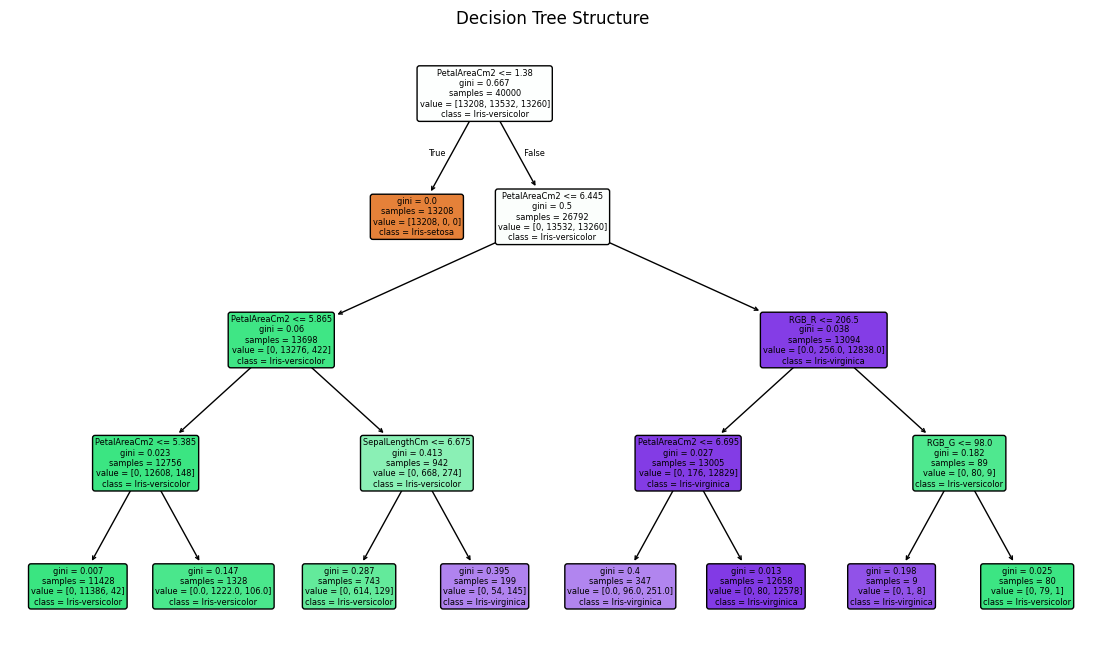

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load the dataset
df = pd.read_csv("/content/iris_large_dataset.csv")
print("Dataset Head:")
display(df.head())

# 2. Separate Features (X) and Target (y)
# For the Iris dataset, 'Species' is the target variable. 'FlowerId', 'ObservationId', 'SampleId', 'PlantId' are identifiers.
X = df.drop(columns=['FlowerId', 'ObservationId', 'SampleId', 'PlantId', 'Species'])  # Features
y = df['Species']   # Target

# Handle non-numeric columns in X if any exist (already handled by dropping identifier/target columns)
object_cols = X.select_dtypes(include=['object']).columns
if len(object_cols) > 0:
    print(f"Dropping {len(object_cols)} non-numeric columns from X: {list(object_cols)}")
    X = X.drop(columns=object_cols)

# 3. Encode target variable (y) if categorical
le = LabelEncoder()
# Now y is 'Species' (object dtype), so this block will execute correctly
y = le.fit_transform(y)
class_names = [str(cls) for cls in le.classes_] # Get class names after encoding

# 4. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Initialize and train the Decision Tree Classifier
# You can adjust max_depth to control tree size and prevent overfitting
dt_classifier = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
dt_classifier.fit(X_train, y_train)

# 6. Predict on test set
y_pred = dt_classifier.predict(X_test)

# 7. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"\n--- Decision Tree Classification Results ---")
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

# 8. Visualize the Decision Tree
plt.figure(figsize=(14, 8))
tree.plot_tree(
    dt_classifier,
    filled=True,
    feature_names=X.columns,
    class_names=class_names,
    rounded=True
)
plt.title("Decision Tree Structure")
plt.show()

# EXPERIMENT 7 : KNN CLASSIFIER

In [36]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load the dataset
df = pd.read_csv("/content/KNNAlgorithmDataset-selected-columns.csv")
print("Dataset Head:")
display(df.head())

# 2. Separate Features (X) and Target (y)
# The 'diagnosis' column is the target variable, and 'id' is an identifier, not a feature.
X = df.drop(columns=['id', 'diagnosis'])  # Features: all columns except 'id' and 'diagnosis'
y = df['diagnosis']   # Target: the 'diagnosis' column

# Handle non-numeric columns in X if present (already handled by dropping 'id' and 'diagnosis' if they were the only non-numeric in X)
object_cols = X.select_dtypes(include=['object']).columns
if len(object_cols) > 0:
    print(f"Dropping {len(object_cols)} non-numeric columns from X: {list(object_cols)}")
    X = X.drop(columns=object_cols)

# 3. Encode categorical target labels (the 'diagnosis' column is categorical)
# This block will now correctly execute as y is of 'object' dtype.
le = LabelEncoder()
y = le.fit_transform(y)

# 4. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Feature Scaling (Crucial for KNN since it is distance-based)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Initialize and Train the KNN Model
k = 3  # Number of neighbors
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train_scaled, y_train)

# 7. Make Predictions
y_pred = knn.predict(X_test_scaled)

# 8. Evaluate the Model
accuracy = accuracy_score(y_test, y_pred)
print(f"\n--- KNN Classification Results (k={k}) ---")
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Dataset Head:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430



--- KNN Classification Results (k=3) ---
Model Accuracy: 95.61%

Classification Report:
              precision    recall  f1-score   support

           B       0.97      0.96      0.96        71
           M       0.93      0.95      0.94        43

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



 # TO PERFORM K-MEAN AND K-MEDOID CLUSTERING
# EXP 8

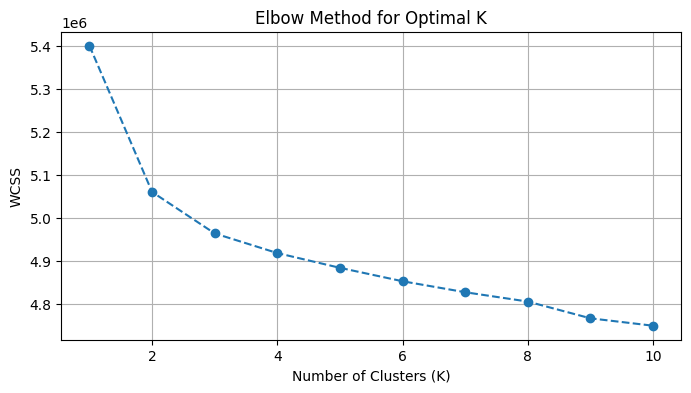

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 1. Load the dataset (Replace filename as needed)
df = pd.read_csv("/content/iris_large_dataset.csv")

# 2. Preprocess features (drop identifiers / non-numeric columns)
object_cols = df.select_dtypes(include=['object']).columns
X = df.drop(columns=object_cols)

# Handle missing values if any
X = X.fillna(X.mean())

# 3. Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Determine Optimal Clusters (Elbow Method for K-Means)
wcss = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

# 5. Fit K-Means & K-Medoids (Using K=3 as default)
n_clusters = 3

# K-Means
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# K-Medoids
kmedoids = KMedoids(n_clusters=n_clusters, random_state=42, method='pam')
kmedoids_labels = kmedoids.fit_predict(X_scaled)

# 6. Model Evaluation (Silhouette Score)
score_kmeans = silhouette_score(X_scaled, kmeans_labels)
score_kmedoids = silhouette_score(X_scaled, kmedoids_labels)

print("--- Clustering Evaluation ---")
print(f"K-Means Silhouette Score:   {score_kmeans:.4f}")
print(f"K-Medoids Silhouette Score: {score_kmedoids:.4f}\n")

# 7. Reduce dimensionality for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plotting K-Means vs K-Medoids
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot K-Means
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.6, edgecolors='k')
axes[0].set_title(f"K-Means Clustering (Silhouette: {score_kmeans:.2f})")
axes[0].set_xlabel("PCA Component 1")
axes[0].set_ylabel("PCA Component 2")

# Plot K-Medoids
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=kmedoids_labels, cmap='plasma', alpha=0.6, edgecolors='k')
axes[1].set_title(f"K-Medoids Clustering (Silhouette: {score_kmedoids:.2f})")
axes[1].set_xlabel("PCA Component 1")
axes[1].set_ylabel("PCA Component 2")

plt.tight_layout()
plt.show()